# T18: arbitration and reliability gates

Regenerates every figure in `README.md` from `data/` (small tables extracted from the gitignored `runs/t18_cache_*` diagnostic caches by `make_data.py`) and from the scorecard / pb_scan output directories `runs/t18_{before,after}_*`. The example figure re-simulates five frozen example light curves (`data/example_params.json`) and runs the pipeline with the T18 gates off and on (~1 min).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
sys.path.insert(0, str(Path('../../claude_files').resolve()))
import determinism; determinism.pin_blas_threads()
import matplotlib; matplotlib.rcParams['figure.max_open_warning'] = 0
import figs
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70)
RUNS = Path('../../runs')

## 1. Diagnosis: why seed-0 stars were lost (pre-T18)
Categories: no fitted success candidate at all (a Stage 1 problem); the best success candidate failed one of the four comb-shape gates; or it passed every gate but another candidate was selected.

category           outcome
lost_on_selection  half        1
                   wrong       6
never_proposed     half        2
                   none       22
                   wrong       4
succ_failed_gate   half        3
                   none       15
                   wrong       2
dtype: int64

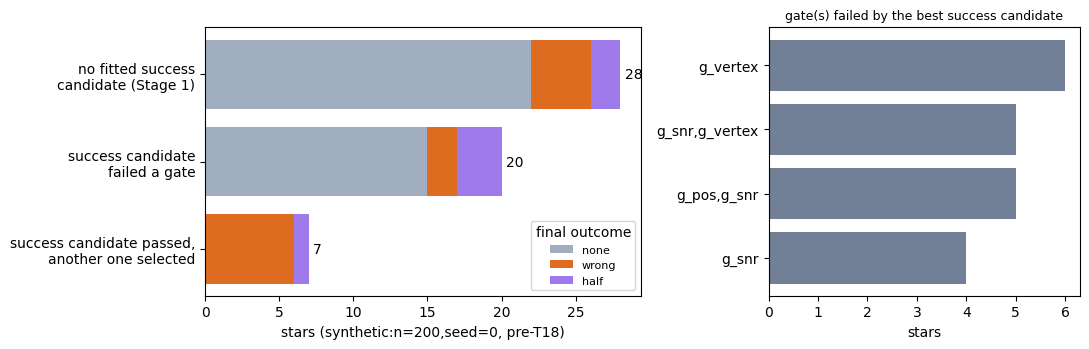

In [2]:
lost = pd.read_csv('data/lost_s0.csv')
figs.fig_lost_categories(lost);
lost.groupby(['category', 'outcome']).size()

Lost on selection: in every case the winner was a ~0.2-0.5 d comb with mean half-lag contrast ~0.

In [3]:
cols = ['star_id', 'P_true', 'snr', 'outcome', 'succ_P', 'succ_acf_half_lag_contrast', 'sel_P', 'sel_acf_half_lag_contrast', 'sel_redchi', 'succ_redchi']
lost[lost.category == 'lost_on_selection'][cols].round(4)

,star_id,P_true,snr,outcome,succ_P,succ_acf_half_lag_contrast,sel_P,sel_acf_half_lag_contrast,sel_redchi,succ_redchi
0,synth-s0-00001,18.7907,1.1058,wrong,17.4600,0.2073,0.2201,-0.0031,0.0000,0.0001
15,synth-s0-00064,37.4706,3.4713,wrong,37.3551,1.1054,0.2369,-0.0027,0.0000,0.0002
16,synth-s0-00068,27.5915,2.0493,wrong,31.5189,0.1267,0.1694,0.0041,0.0000,0.0002
21,synth-s0-00078,2.4805,5.7260,wrong,2.2123,0.0794,0.4410,0.0105,0.0000,0.0006
27,synth-s0-00091,2.2237,1.3894,wrong,2.4968,0.0286,0.2000,0.0052,0.0001,0.0001
30,synth-s0-00099,32.4033,1.1077,wrong,32.3777,0.2650,0.1716,0.0076,0.0000,0.0001
52,synth-s0-00172,0.5005,2.6071,half,0.5037,0.0220,0.2476,-0.0071,0.0001,0.0001


Noise false positives on the pb_scan dev seeds (offset 500): selected candidate's gate values and features.

In [4]:
pd.read_csv('data/fp_pbdev.csv').round(3)

,star_id,red,n_sectors,lag_max,P,redchi,n_peaks_used,n_peaks_required,few_peaks,frac_pos,mean_hsnr,frac_vertex,mean_h,acf_height_at_P,acf_half_lag_contrast,fold_half_corr,fold_half_corr_at_2P,pdm_theta,n_methods,n_teeth_available
0,pb-noise-red-1s-901501,True,1,18.792,0.221,0.001,8,4,False,1.0,1.633,1.000,0.238,0.308,-0.011,-0.189,-0.045,1.004,1,8
1,pb-noise-red-1s-901503,True,1,18.792,0.250,0.000,8,4,False,1.0,2.044,1.000,0.323,0.428,-0.014,-0.238,0.028,1.001,2,8
2,pb-noise-red-1s-901505,True,1,18.792,0.231,0.000,8,4,False,1.0,1.718,1.000,0.237,0.391,-0.019,-0.105,-0.031,1.000,1,8
3,pb-noise-red-1s-901507,True,1,18.792,0.181,0.000,8,4,False,1.0,1.708,1.000,0.436,0.501,-0.004,-0.149,-0.023,1.004,1,8
4,pb-noise-red-1s-901509,True,1,18.792,0.229,0.000,6,4,False,1.0,1.595,1.000,0.167,0.311,-0.025,-0.158,-0.141,1.005,1,8
5,pb-noise-red-1s-901511,True,1,18.792,0.284,0.000,7,4,False,1.0,1.535,1.000,0.227,0.329,-0.011,-0.189,-0.125,1.002,1,8
6,pb-noise-red-1s-901513,True,1,18.792,0.198,0.001,8,4,False,1.0,2.399,1.000,0.355,0.451,-0.023,-0.201,-0.159,1.006,1,8
7,pb-noise-red-1s-901515,True,1,18.792,0.170,0.001,7,4,False,1.0,2.270,0.857,0.279,0.408,-0.016,-0.261,-0.121,1.005,1,8
8,pb-noise-red-1s-901517,True,1,18.792,0.253,0.000,5,4,False,1.0,1.169,1.000,0.235,0.421,-0.011,-0.228,-0.106,0.998,1,8
9,pb-noise-red-1s-901519,True,1,18.792,0.319,0.000,7,4,False,1.0,1.208,1.000,0.161,0.314,-0.014,-0.181,-0.098,1.003,1,8


## 2. The half-lag consistency gate
Each point is a pre-T18 *selected* answer. x = the smallest of the terms h(kP) - h((k-1/2)P); y = their mean (`acf_half_lag_contrast`). The new gate rejects the shaded quadrant (some term <= 0 and mean < 0.1). Left: tuning data; right: held-out validation.

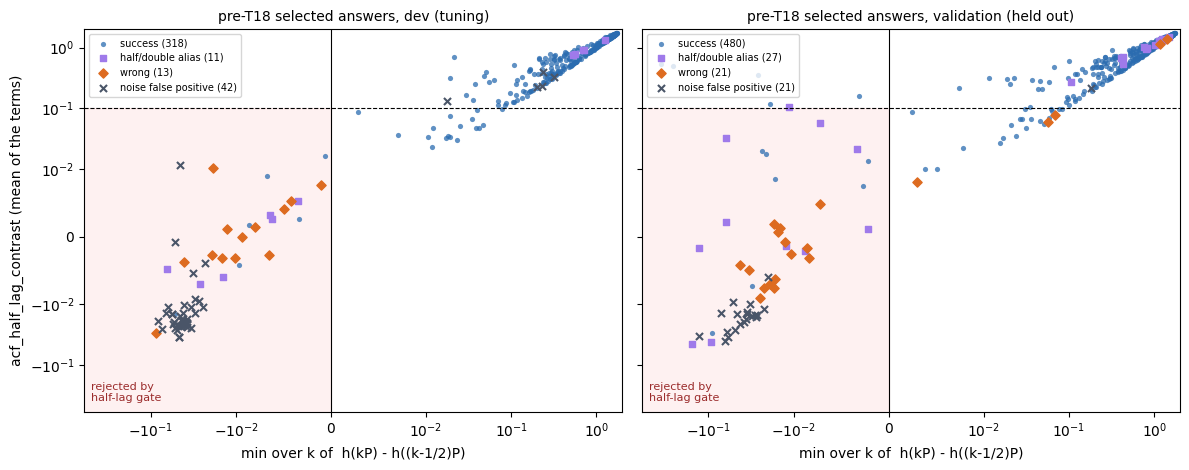

In [5]:
sel = pd.read_csv('data/selected_base.csv')
figs.fig_contrast_gate(sel);

## 3. The few-peak ACF-height guard

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
correct,419.0,0.885,0.079,0.538,0.843,0.907,0.938,1.023
diffrot,3.0,0.760,0.024,0.732,0.753,0.774,0.774,0.774
double,107.0,0.827,0.208,0.084,0.848,0.895,0.934,1.010
half,17.0,0.424,0.137,0.299,0.326,0.375,0.409,0.697
noise,13.0,0.162,0.076,0.046,0.125,0.152,0.190,0.294
wrong,3.0,0.902,0.063,0.833,0.874,0.915,0.936,0.958


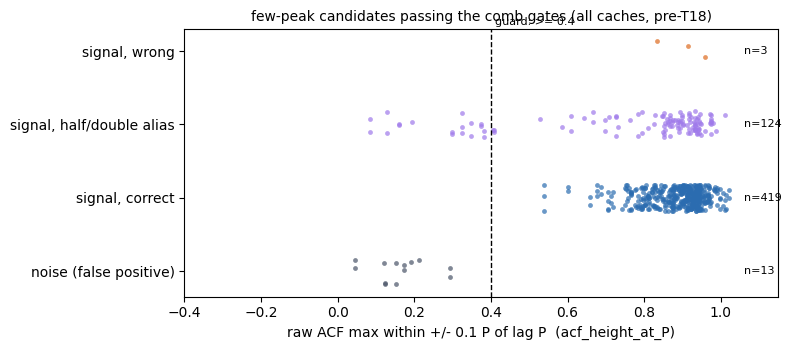

In [6]:
few = pd.read_csv('data/few_peak_cands.csv')
figs.fig_few_peak_guard(few);
few.assign(group=few.kind.where(few.kind == 'noise', few.label)).groupby('group').acf_height_at_P.describe().round(3)

## 4. Gate ablation (offline replay of the arbitration on the caches)
`arbitration.replay` re-applies a gating / selection rule to the cached candidate fits; with the pre-T18 rule it reproduces every cached pipeline outcome (0 mismatches on all 5 caches), and with the recommended rule it reproduces the real post-change scorecards star by star. Thresholds were chosen on the dev rows only.

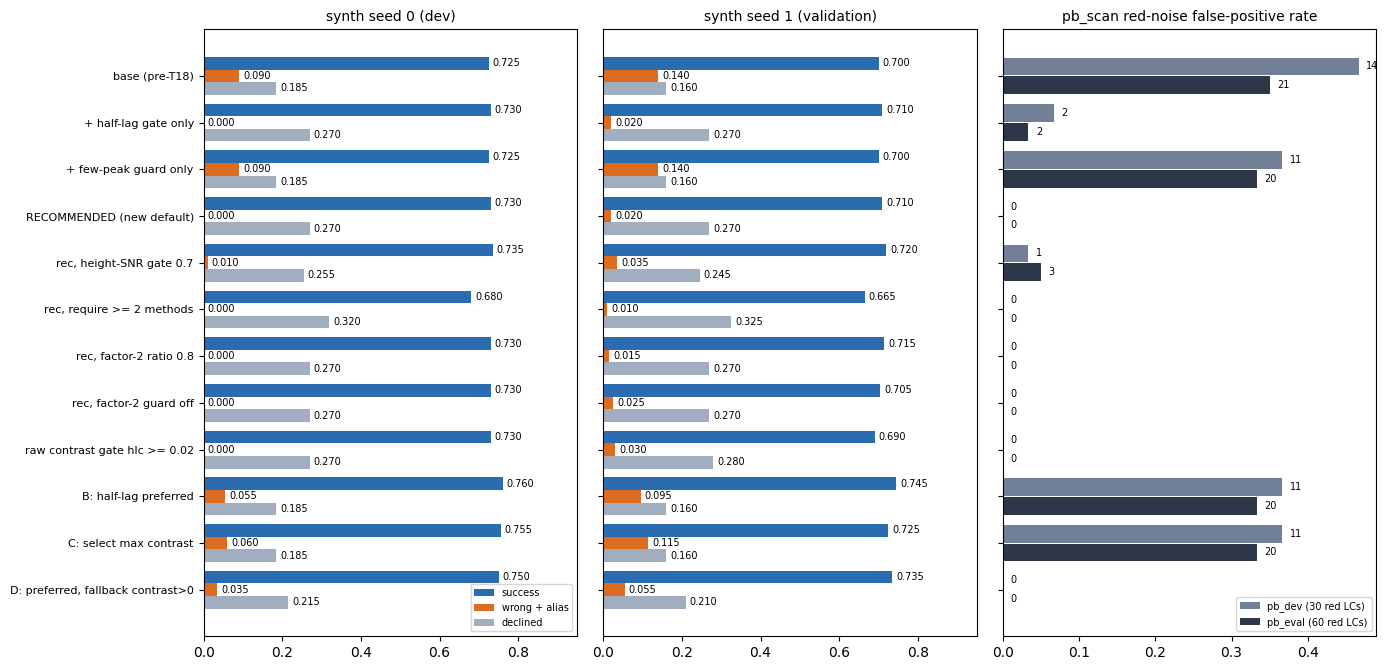

In [7]:
abl = pd.read_csv('data/ablation.csv')
rules = ['base (pre-T18)', '+ half-lag gate only', '+ few-peak guard only', 'RECOMMENDED: half-lag gate + few-peak guard', 'rec, height-SNR gate 0.7', 'rec, require >= 2 methods', 'rec, factor-2 ratio 0.8', 'rec, factor-2 guard off', 'raw contrast gate hlc >= 0.02', 'B: half-lag PREFERRED, else base gates', 'C: base gates, select max contrast', 'D: half-lag preferred, else base gates + contrast > 0']
short = {'RECOMMENDED: half-lag gate + few-peak guard': 'RECOMMENDED (new default)', 'D: half-lag preferred, else base gates + contrast > 0': 'D: preferred, fallback contrast>0', 'B: half-lag PREFERRED, else base gates': 'B: half-lag preferred', 'C: base gates, select max contrast': 'C: select max contrast'}
figs.fig_ablation(abl, rules, short);

In [8]:
view = abl.pivot_table(index='rule', columns='dataset', values=['success', 'wrong', 'alias', 'none', 'fp_red'])
view.loc[[r for r in abl.rule.unique()]].round(3)

alias                           fp_red                         none                           success                            wrong          \
dataset                                               pb_dev pb_eval synth_s0 synth_s1 pb_dev pb_dev_noise2 pb_eval pb_dev pb_eval synth_s0 synth_s1  pb_dev pb_eval synth_s0 synth_s1 pb_dev pb_eval   
rule                                                                                                                                                                                                    
base (pre-T18)                                         0.025   0.043    0.030    0.050   14.0          28.0    21.0  0.096   0.091    0.185    0.160   0.874   0.859    0.725    0.700  0.005   0.008   
+ half-lag gate only                                   0.025   0.038    0.000    0.005    2.0           4.0     2.0  0.101   0.093    0.270    0.270   0.874   0.864    0.730    0.710  0.000   0.005   
+ few-peak guard only                                  0.015   0.035    0.030    0.050   11.0          26.0    20.0  0.106   0.098    0.185    0.160   0.874   0.859    0.725    0.700  0.005   0.008   
RECOMMENDED: half-lag gate + few-peak guard            0.015   0.030    0.000    0.005    0.0           1.0     0.0  0.111   0.101    0.270    0.270   0.874   0.864    0.730    0.710  0.000   0.005   
rec, half-lag 'all terms > 0' only (no 0.1 escape)     0.015   0.030    0.000    0.000    0.0           1.0     0.0  0.111   0.106    0.275    0.270   0.874   0.859    0.725    0.715  0.000   0.005   
rec, few-peak guard 0.3                                0.025   0.035    0.000    0.005    0.0           1.0     0.0  0.101   0.096    0.270    0.270   0.874   0.864    0.730    0.710  0.000   0.005   
rec, few-peak guard 0.5                                0.015   0.028    0.000    0.005    0.0           1.0     0.0  0.111   0.104    0.270    0.270   0.874   0.864    0.730    0.710  0.000   0.005   
rec, few-peak guard = PDM theta <= 0.7                 0.025   0.038    0.000    0.005    0.0           1.0     0.0  0.101   0.093    0.270    0.270   0.874   0.864    0.730    0.710  0.000   0.005   
rec, factor-2 guard off                                0.081   0.086    0.000    0.010    0.0           1.0     0.0  0.111   0.101    0.270    0.270   0.808   0.808    0.730    0.705  0.000   0.005   
rec, factor-2 ratio 0.6                                0.020   0.033    0.000    0.005    0.0           1.0     0.0  0.111   0.101    0.270    0.270   0.869   0.861    0.730    0.710  0.000   0.005   
rec, factor-2 ratio 0.8                                0.015   0.025    0.000    0.000    0.0           1.0     0.0  0.111   0.101    0.270    0.270   0.874   0.869    0.730    0.715  0.000   0.005   
rec, factor-2 by fold_half_corr_at_2P < 0.5            0.025   0.040    0.005    0.000    0.0           1.0     0.0  0.111   0.101    0.270    0.270   0.864   0.854    0.725    0.715  0.000   0.005   
rec, select max contrast                               0.015   0.030    0.000    0.000    0.0           1.0     0.0  0.111   0.101    0.270    0.270   0.874   0.864    0.730    0.715  0.000   0.005   
rec, select redchi / n_methods                         0.015   0.030    0.000    0.005    0.0           1.0     0.0  0.111   0.101    0.270    0.270   0.874   0.864    0.730    0.710  0.000   0.005   
rec, require >= 2 methods                              0.030   0.038    0.000    0.000    0.0           0.0     0.0  0.288   0.250    0.320    0.325   0.682   0.707    0.680    0.665  0.000   0.005   
rec, vertex gate 0.5                                   0.015   0.030    0.000    0.005    0.0           1.0     0.0  0.106   0.096    0.270    0.265   0.879   0.866    0.730    0.715  0.000   0.008   
rec, height-SNR gate 0.7                               0.015   0.030    0.005    0.005    1.0           7.0     3.0  0.111   0.101    0.255    0.245   0.874   0.864    0.735    0.720  0.000   0.005   
rec, height-SNR gate 0.5           

## 5. Before / after on the real benchmarks

,"synthetic:n=200,seed=0","synthetic:n=200,seed=1","synthetic:n=200,seed=0","synthetic:n=200,seed=1"
,before,before,after,after
n,200.000,200.000,200.00,200.000
correct,0.495,0.435,0.50,0.460
diffrot,0.230,0.265,0.23,0.250
half,0.030,0.045,0.00,0.005
double,0.000,0.005,0.00,0.000
wrong,0.060,0.090,0.00,0.015
none,0.185,0.160,0.27,0.270
success,0.725,0.700,0.73,0.710
alias,0.030,0.050,0.00,0.005


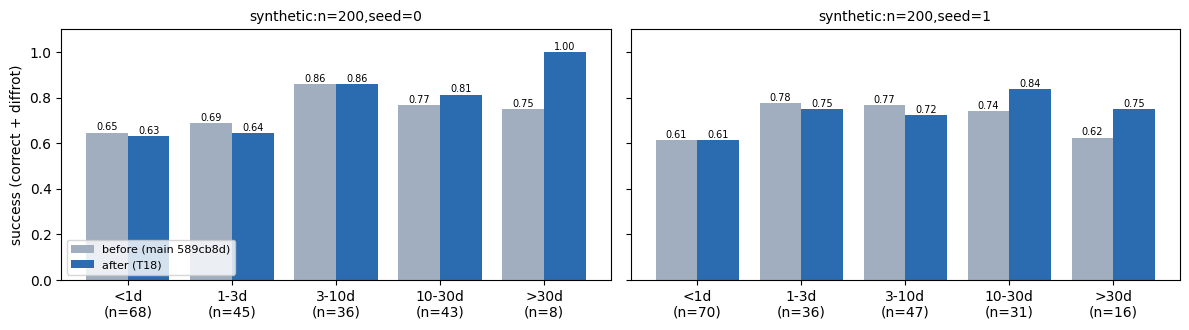

In [9]:
before = {f'synthetic:n=200,seed={s}': json.load(open(RUNS / f't18_before_s{s}/metrics.json')) for s in (0, 1)}
after = {f'synthetic:n=200,seed={s}': json.load(open(RUNS / f't18_after_s{s}/metrics.json')) for s in (0, 1)}
figs.fig_bins(before, after);
pd.DataFrame({(k, w): d[k]['final']['overall'] for w, d in (('before', before), ('after', after)) for k in d}).round(3)

In [10]:
rows = []
for t in ('eval', 'dev'):
    for w in ('before', 'after'):
        s = json.load(open(RUNS / f't18_{w}_pb_{t}/summary.json'))
        rows.append(dict(set=t, run=w, **s['overall'], fp_red=s['noise_false_positive']['red'], fp_white=s['noise_false_positive']['white']))
pd.DataFrame(rows).round(3)

,set,run,correct_all,correct_PB_le_0.33,correct_PB_le_0.07,alias_all,wrong_all,fp_red,fp_white
0,eval,before,0.859,0.944,0.944,0.043,0.008,0.350,0.0
1,eval,after,0.864,0.950,0.954,0.030,0.005,0.000,0.0
2,dev,before,0.874,0.961,0.944,0.025,0.005,0.467,0.0
3,dev,after,0.874,0.961,0.944,0.015,0.000,0.000,0.0


pb_scan correct fraction by P/B (pooled over 1/2/13 sectors), evaluation seeds.

In [11]:
def pb(w):
    r = pd.read_csv(RUNS / f't18_{w}_pb_eval/rows.csv'); s = r[r.kind == 'signal']
    return s.groupby('P_over_B').outcome.apply(lambda o: (o == 'correct').mean())
pd.DataFrame({'before': pb('before'), 'after': pb('after')}).round(3).T

P_over_B,0.02,0.04,0.07,0.10,0.13,0.17,0.20,0.25,0.30,0.33,0.40
before,0.917,0.972,0.944,0.944,1.0,0.972,1.0,0.944,1.0,0.75,0.0
after,0.917,0.972,0.972,0.972,1.0,0.972,1.0,0.944,1.0,0.75,0.0


## 6. Example failure modes (frozen light curves; gates off = pre-T18, gates on = T18)
Orange: the pre-T18 pick's fitted comb. Blue: the best success candidate (or another candidate). Right column: zoom on the pre-T18 pick, with its kP (solid) and (k-1/2)P (dotted) lags; the gate asks whether the ACF is higher at every solid line than at the dotted line before it.

,star,pre_T18,T18
0,synth-s0-00064,0.2369,37.36
1,pb-noise-red-1s-901501,0.2215,declined
2,pb-noise-red-2s-902501,16.24,declined
3,synth-s0-00175,1.117,declined
4,synth-s0-00144,declined,declined


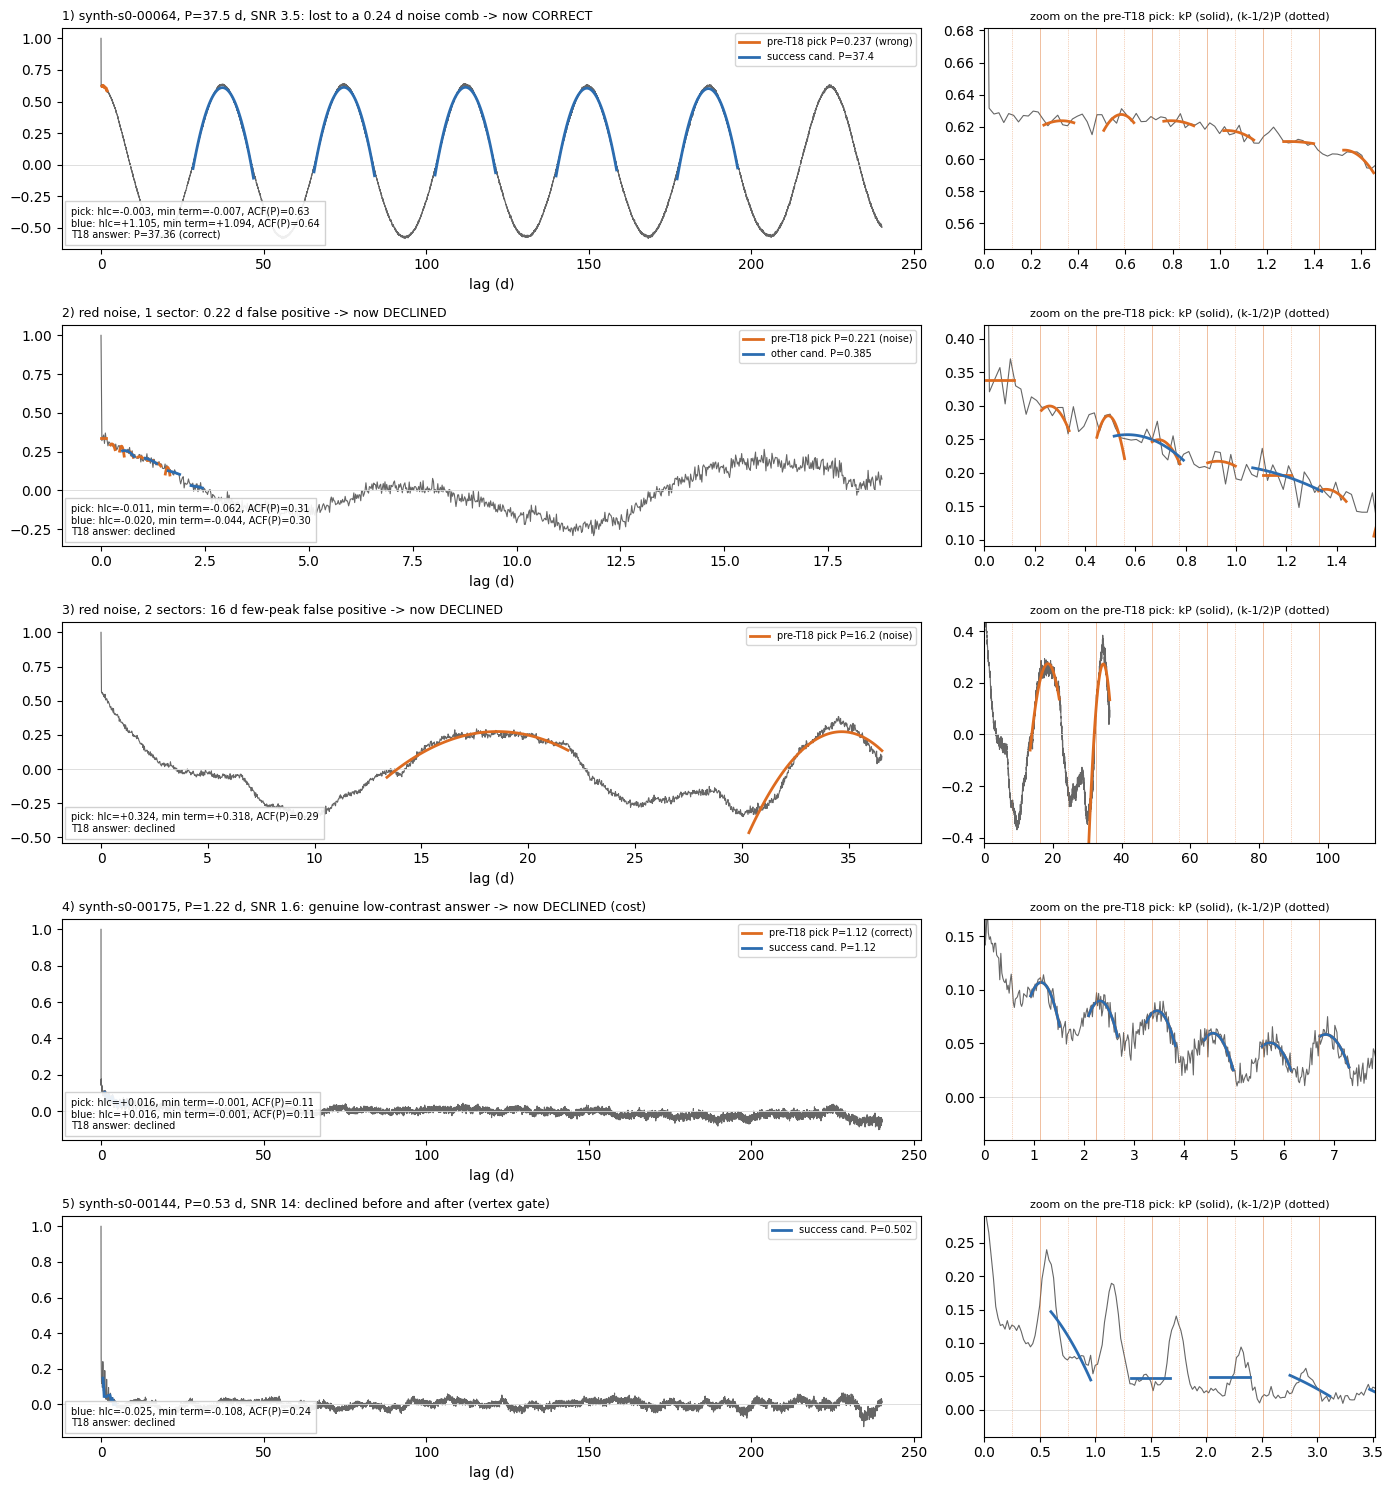

In [12]:
fig, ex = figs.fig_examples()
ex